# E2 — MobileNetV2 con fine-tuning parcial | Clasificación de enfermedades de la yuca

**Objetivo:** comprobar si soltar las últimas capas del backbone MobileNetV2 mejora el resultado de E1 (comparación secundaria **E1 vs E2**, hipótesis H3).

**Protocolo:** parte del mejor modelo de E1 (`mejor_modelo_e1.keras`); se descongelan las **últimas 20 capas** del backbone **manteniendo congeladas las BatchNorm**; Adam con **lr 1e-5**; **hasta 10 épocas más** con `EarlyStopping(patience=4)` sobre `val_loss`; semilla **42**; 224×224; batch 8 y **sin aumento de datos** (igual que E1).

**Métrica principal:** Macro-F1 en validación. **No se evalúa el conjunto de prueba.**

**Importante:** el pipeline de datos es idéntico al de E1. El modelo ya incluye su capa `Rescaling` ([0,255] → [-1,1]), por eso aquí **no** se aplica `preprocess_input`.

## 1. Entorno y reproducibilidad

In [1]:
%pip -q install tensorflow-datasets importlib_resources psutil

In [2]:
import os, time, gc, math, json
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import psutil

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 8            # igual que E1
EPOCHS_FT = 10            # épocas adicionales de fine-tuning (máximo)
LR_FT = 1e-5
ULTIMAS_CAPAS = 20
NUM_CLASSES = 5
CLASS_NAMES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
OUTPUT_DIR = "results/e2"
RUTA_E1 = "results/e1/mejor_modelo_e1.keras"
os.makedirs(OUTPUT_DIR, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print(f"RAM disponible: {psutil.virtual_memory().available/1024**3:.2f} GB")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM disponible: 10.77 GB


## 2. Manifiesto depurado y particiones idénticas a E0 y E1

In [3]:
URL_MANIFIESTO = (
    "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/"
    "main/results/eda/manifiesto_final_conservados.csv"
)
df_manifest = pd.read_csv(URL_MANIFIESTO)
assert {"particion", "indice"}.issubset(df_manifest.columns)
assert len(df_manifest) == 9361
assert not df_manifest.duplicated(["particion", "indice"]).any()
print(df_manifest.groupby("particion").size())

particion
test          1874
train         5610
validation    1877
dtype: int64


In [4]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava:0.1.0",
    split=["train", "validation", "test"],
    as_supervised=True, with_info=True, shuffle_files=False
)

def aplicar_manifiesto(ds, particion):
    total = int(tf.data.experimental.cardinality(ds).numpy())
    indices = set(df_manifest.loc[
        df_manifest["particion"] == particion, "indice"
    ].astype(int))
    assert indices and min(indices) >= 0 and max(indices) < total
    mascara = tf.constant([i in indices for i in range(total)], dtype=tf.bool)
    filtrado = (ds.enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato, num_parallel_calls=1))
    # El filtro pierde la cardinalidad; restaurarla evita errores de Keras
    return filtrado.apply(tf.data.experimental.assert_cardinality(len(indices)))

ds_train_final = aplicar_manifiesto(ds_train, "train")
ds_val_final = aplicar_manifiesto(ds_val, "validation")
ds_test_final = aplicar_manifiesto(ds_test, "test")
n_train, n_val, n_test = (
    int(tf.data.experimental.cardinality(ds).numpy())
    for ds in (ds_train_final, ds_val_final, ds_test_final)
)
assert (n_train, n_val, n_test) == (5610, 1877, 1874)
print("Train:", n_train, "| Validación:", n_val, "| Test reservado:", n_test)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Train: 5610 | Validación: 1877 | Test reservado: 1874


La verificación SHA-256 completa se realizó en E0. Aquí se reutiliza el **mismo manifiesto** y se verifican sus cantidades.

## 3. Pipeline de datos (idéntico a E1)

El modelo normaliza internamente, así que la función solo redimensiona y convierte a `float32` en el rango [0, 255].

In [5]:
def preprocesar(imagen, etiqueta):
    imagen = tf.image.resize(imagen, IMG_SIZE, method="bilinear")
    imagen = tf.cast(imagen, tf.float32)
    return imagen, tf.cast(etiqueta, tf.int32)

# Mezclar ANTES de convertir las imágenes a float32 de 224x224 (ahorra RAM).
train_ds = (ds_train_final
    .shuffle(512, seed=SEED, reshuffle_each_iteration=True)
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))
val_ds = (ds_val_final
    .map(preprocesar, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1))
# El conjunto de prueba no se procesa ni evalúa en este notebook.

x_batch, y_batch = next(iter(train_ds))
print("Batch:", x_batch.shape, x_batch.dtype, y_batch.shape)
print("Rango:", float(tf.reduce_min(x_batch)), float(tf.reduce_max(x_batch)))
assert x_batch.shape == (BATCH_SIZE, 224, 224, 3)
assert 0 <= float(tf.reduce_min(x_batch)) <= float(tf.reduce_max(x_batch)) <= 255
del x_batch, y_batch
gc.collect()

Batch: (8, 224, 224, 3) <dtype: 'float32'> (8,)
Rango: 0.0 255.0


3077

## 4. Punto de partida: modelo E1

Se carga el mejor modelo de E1 y se evalúa con el mismo código que se usará para E2. Así la comparación E1 vs E2 se hace con **métricas calculadas en esta misma sesión**.

Si el archivo no está en `results/e1/`, la celda te pide subirlo (`mejor_modelo_e1.keras`).

In [6]:
if not os.path.exists(RUTA_E1):
    from google.colab import files
    os.makedirs(os.path.dirname(RUTA_E1), exist_ok=True)
    print("Sube el archivo mejor_modelo_e1.keras")
    subido = files.upload()
    os.replace(next(iter(subido)), RUTA_E1)
assert os.path.exists(RUTA_E1), "Falta mejor_modelo_e1.keras"

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Solo etiquetas, no imágenes completas en RAM.
y_true = np.concatenate([y.numpy() for _, y in val_ds])
assert len(y_true) == n_val

def evaluar(modelo):
    # Warm-up para medir inferencia sin incluir la primera compilación.
    _ = modelo.predict(val_ds.take(2), verbose=0)
    inicio = time.perf_counter()
    probs = modelo.predict(val_ds, verbose=0)
    t_inf = time.perf_counter() - inicio
    assert probs.shape == (n_val, NUM_CLASSES)
    pred = probs.argmax(axis=1)
    return {
        "probs": probs,
        "pred": pred,
        "accuracy": accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "f1_clase": f1_score(y_true, pred, average=None,
                             labels=range(NUM_CLASSES), zero_division=0),
        "ms_por_imagen": t_inf / n_val * 1000,
    }

modelo_e1 = tf.keras.models.load_model(RUTA_E1)
res_e1 = evaluar(modelo_e1)
params_e1_entrenables = sum(int(np.prod(w.shape)) for w in modelo_e1.trainable_weights)
params_e1_totales = modelo_e1.count_params()
tamano_e1_mb = os.path.getsize(RUTA_E1) / 1024**2

print(f"E1  Accuracy: {res_e1['accuracy']:.4f} | Macro-F1: {res_e1['macro_f1']:.4f} "
      f"| {res_e1['ms_por_imagen']:.2f} ms/imagen")
print("Parámetros entrenables E1:", params_e1_entrenables)
del modelo_e1
gc.collect()

Sube el archivo mejor_modelo_e1.keras


Saving mejor_modelo_e1.keras to mejor_modelo_e1.keras
E1  Accuracy: 0.7645 | Macro-F1: 0.6777 | 10.46 ms/imagen
Parámetros entrenables E1: 164613


41184

## 5. Modelo E2: descongelar las últimas 20 capas del backbone (BatchNorm congeladas)

Se carga una copia limpia del modelo de E1 y se modifica qué capas se entrenan. **Después hay que recompilar**; de lo contrario el cambio no se aplica.

In [7]:
modelo_e2 = tf.keras.models.load_model(RUTA_E1)
base = next(c for c in modelo_e2.layers if isinstance(c, tf.keras.Model))
print("Backbone:", base.name, "| capas:", len(base.layers))

base.trainable = True
for capa in base.layers[:-ULTIMAS_CAPAS]:
    capa.trainable = False
for capa in base.layers[-ULTIMAS_CAPAS:]:
    capa.trainable = not isinstance(capa, tf.keras.layers.BatchNormalization)

ultimas = base.layers[-ULTIMAS_CAPAS:]
n_bn = sum(isinstance(c, tf.keras.layers.BatchNormalization) for c in ultimas)
print(f"De las últimas {ULTIMAS_CAPAS} capas, {n_bn} son BatchNorm (quedan congeladas)")
assert all(not c.trainable for c in base.layers[:-ULTIMAS_CAPAS])
assert all(not c.trainable for c in ultimas
           if isinstance(c, tf.keras.layers.BatchNormalization))

modelo_e2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FT),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
params_entrenables = sum(int(np.prod(w.shape)) for w in modelo_e2.trainable_weights)
params_totales = modelo_e2.count_params()
print("Parámetros entrenables E2:", params_entrenables, "(E1:", params_e1_entrenables, ")")
print("Parámetros totales:", params_totales)
assert params_entrenables > params_e1_entrenables, "El fine-tuning no descongeló nada"

Backbone: mobilenetv2_1.00_224 | capas: 154
De las últimas 20 capas, 7 son BatchNorm (quedan congeladas)
Parámetros entrenables E2: 1359493 (E1: 164613 )
Parámetros totales: 2422597


## 6. Entrenamiento (máximo 10 épocas, EarlyStopping paciencia 4)

El checkpoint guarda el modelo con la menor `val_loss`. Si el fine-tuning no mejora a E1, ese también es un resultado válido para H3.

In [8]:
class MonitorMemoria(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mem = psutil.virtual_memory()
        print(f"RAM al terminar época {epoch+1}: {mem.percent:.1f}% "
              f"| disponible {mem.available/1024**3:.2f} GB")

RUTA_E2 = os.path.join(OUTPUT_DIR, "mejor_modelo_e2.keras")
callbacks_e2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=RUTA_E2, monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.CSVLogger(
        os.path.join(OUTPUT_DIR, "historial_entrenamiento.csv")
    ),
    MonitorMemoria(),
]

inicio = time.perf_counter()
historial_e2 = modelo_e2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FT,
    callbacks=callbacks_e2,
    verbose=1
)
tiempo_entrenamiento_e2 = time.perf_counter() - inicio
epocas_ejecutadas = len(historial_e2.history["loss"])
mejor_epoca = int(np.argmin(historial_e2.history["val_loss"])) + 1
print(f"Tiempo: {tiempo_entrenamiento_e2:.2f} s")
print("Épocas ejecutadas:", epocas_ejecutadas, "| mejor época (val_loss):", mejor_epoca)

Epoch 1/10
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7922 - loss: 0.5747RAM al terminar época 1: 23.8% | disponible 9.66 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 59s 65ms/step - accuracy: 0.7973 - loss: 0.5641 - val_accuracy: 0.7869 - val_loss: 0.6067
Epoch 2/10
701/702 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8178 - loss: 0.5104RAM al terminar época 2: 28.4% | disponible 9.08 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 25s 33ms/step - accuracy: 0.8242 - loss: 0.4915 - val_accuracy: 0.7810 - val_loss: 0.6430
Epoch 3/10
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8470 - loss: 0.4503RAM al terminar época 3: 31.3% | disponible 8.71 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.8435 - loss: 0.4457 - val_accuracy: 0.7954 - val_loss: 0.5754
Epoch 4/10
699/702 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8520 - loss: 0.4054RAM al terminar época 4: 33.0% | disponible 8.49 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 24s 33ms/step - accuracy: 0.8583 - loss: 0.3926 - val_accuracy

**Nota:** si Colab se reinicia, los archivos de `/content` se pierden. Descarga `results/e2` al terminar.

## 7. Evaluación en validación (sin usar test)

Se recarga el mejor checkpoint para garantizar que se evalúa el modelo con menor `val_loss`.

In [9]:
modelo_e2 = tf.keras.models.load_model(RUTA_E2)
res_e2 = evaluar(modelo_e2)
y_pred = res_e2["pred"]
probabilidades = res_e2["probs"]
accuracy_e2, macro_f1_e2 = res_e2["accuracy"], res_e2["macro_f1"]
ms_por_imagen = res_e2["ms_por_imagen"]

print(f"Accuracy: {accuracy_e2:.4f}")
print(f"Macro-F1: {macro_f1_e2:.4f}")
print(f"Inferencia: {ms_por_imagen:.2f} ms/imagen")
print(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, zero_division=0
))

Accuracy: 0.7954
Macro-F1: 0.7182
Inferencia: 5.04 ms/imagen
              precision    recall  f1-score   support

         cbb       0.66      0.44      0.53       151
        cbsd       0.75      0.78      0.77       479
         cgm       0.77      0.66      0.71       257
         cmd       0.85      0.92      0.88       885
     healthy       0.70      0.70      0.70       105

    accuracy                           0.80      1877
   macro avg       0.75      0.70      0.72      1877
weighted avg       0.79      0.80      0.79      1877



## 8. Guardar métricas y gráficas

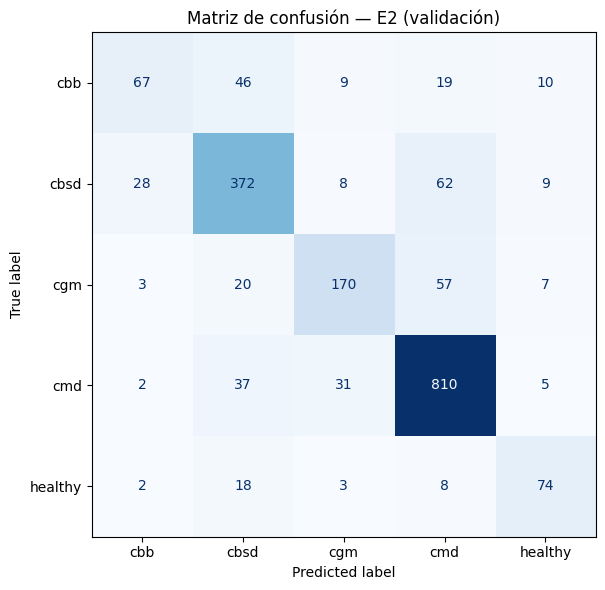

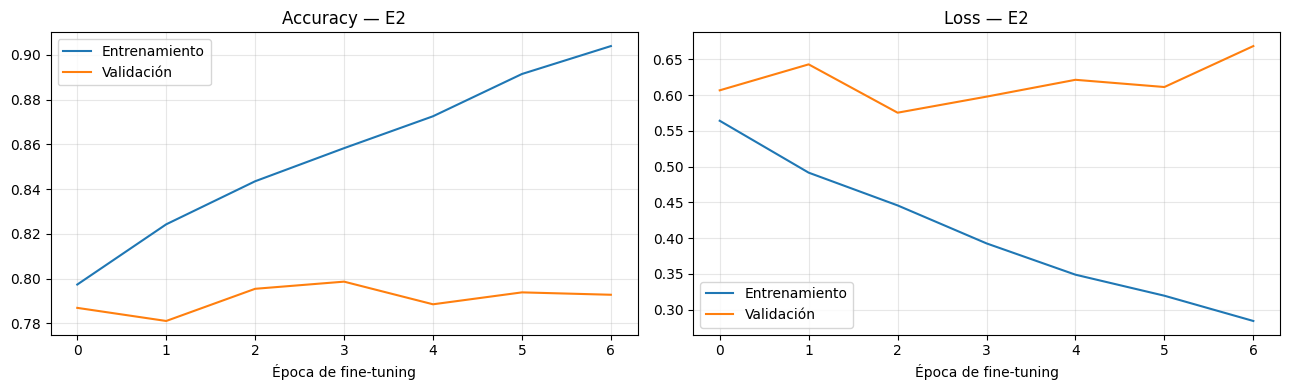

Archivos: ['matriz_confusion.csv', 'resumen_metricas.csv', 'curvas_entrenamiento.png', 'historial_entrenamiento.csv', 'reporte_clasificacion.csv', 'matriz_confusion.png', 'mejor_modelo_e2.keras']


In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

reporte = classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
pd.DataFrame(reporte).T.to_csv(os.path.join(OUTPUT_DIR, "reporte_clasificacion.csv"))
matriz = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
pd.DataFrame(matriz, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    os.path.join(OUTPUT_DIR, "matriz_confusion.csv")
)

tamano_mb = os.path.getsize(RUTA_E2) / 1024**2
pd.DataFrame([{
    "modelo": "E2_MobileNetV2_finetuning",
    "accuracy": accuracy_e2,
    "macro_f1": macro_f1_e2,
    "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e2,
    "epocas_ejecutadas": epocas_ejecutadas,
    "mejor_epoca": mejor_epoca,
    "segundos_por_epoca": tiempo_entrenamiento_e2 / epocas_ejecutadas,
    "ms_inferencia_por_imagen": ms_por_imagen,
    "tamano_modelo_MB": tamano_mb,
    "parametros_entrenables": params_entrenables,
    "parametros_totales": params_totales,
    "capas_descongeladas": ULTIMAS_CAPAS,
    "batch_size": BATCH_SIZE,
    "resolucion": "224x224",
    "learning_rate": LR_FT,
    "semilla": SEED,
}]).to_csv(os.path.join(OUTPUT_DIR, "resumen_metricas.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(matriz, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_title("Matriz de confusión — E2 (validación)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "matriz_confusion.png"), dpi=200)
plt.show()
plt.close(fig)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for ax, clave, titulo in zip(ejes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(historial_e2.history[clave], label="Entrenamiento")
    ax.plot(historial_e2.history["val_" + clave], label="Validación")
    ax.set(xlabel="Época de fine-tuning", title=f"{titulo} — E2")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "curvas_entrenamiento.png"), dpi=200)
plt.show()
plt.close(fig)
print("Archivos:", os.listdir(OUTPUT_DIR))

## 9. Comparación E1 vs. E2 en validación

Los valores de E1 se recalcularon en la sección 4 con el mismo código. Los de E0 se toman de su experimento.

In [11]:
comparacion = pd.DataFrame([
    {"modelo": "E0_CNN", "accuracy": 0.6787, "macro_f1": 0.4699,
     "tiempo_entrenamiento_segundos": 495.67},
    {"modelo": "E1_MobileNetV2_congelada", "accuracy": res_e1["accuracy"],
     "macro_f1": res_e1["macro_f1"],
     "ms_inferencia_por_imagen": res_e1["ms_por_imagen"],
     "tamano_modelo_MB": tamano_e1_mb,
     "parametros_entrenables": params_e1_entrenables,
     "parametros_totales": params_e1_totales},
    {"modelo": "E2_MobileNetV2_finetuning", "accuracy": accuracy_e2,
     "macro_f1": macro_f1_e2,
     "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e2,
     "ms_inferencia_por_imagen": ms_por_imagen,
     "tamano_modelo_MB": tamano_mb,
     "parametros_entrenables": params_entrenables,
     "parametros_totales": params_totales},
])
print(comparacion.to_string(index=False))
comparacion.to_csv(os.path.join(OUTPUT_DIR, "comparacion_e1_e2.csv"), index=False)

f1_clases = pd.DataFrame({
    "clase": CLASS_NAMES,
    "f1_E1": res_e1["f1_clase"],
    "f1_E2": res_e2["f1_clase"],
})
f1_clases["diferencia_E2_menos_E1"] = f1_clases["f1_E2"] - f1_clases["f1_E1"]
print()
print(f1_clases.round(4).to_string(index=False))
f1_clases.to_csv(os.path.join(OUTPUT_DIR, "comparacion_f1_por_clase_e1_e2.csv"), index=False)

delta = macro_f1_e2 - res_e1["macro_f1"]
print(f"\nDiferencia de Macro-F1 (E2 - E1): {delta:+.4f}")

                   modelo  accuracy  macro_f1  tiempo_entrenamiento_segundos  ms_inferencia_por_imagen  tamano_modelo_MB  parametros_entrenables  parametros_totales
                   E0_CNN  0.678700  0.469900                     495.670000                       NaN               NaN                     NaN                 NaN
 E1_MobileNetV2_congelada  0.764518  0.677748                            NaN                 10.464034         11.066140                164613.0           2422597.0
E2_MobileNetV2_finetuning  0.795418  0.718218                     228.552759                  5.035525         20.181704               1359493.0           2422597.0

  clase  f1_E1  f1_E2  diferencia_E2_menos_E1
    cbb 0.4833 0.5296                  0.0463
   cbsd 0.7273 0.7654                  0.0382
    cgm 0.6808 0.7113                  0.0305
    cmd 0.8605 0.8800                  0.0195
healthy 0.6369 0.7048                  0.0679

Diferencia de Macro-F1 (E2 - E1): +0.0405


## 10. Inspección de ocho errores de E2 (sin cargar todas las imágenes)

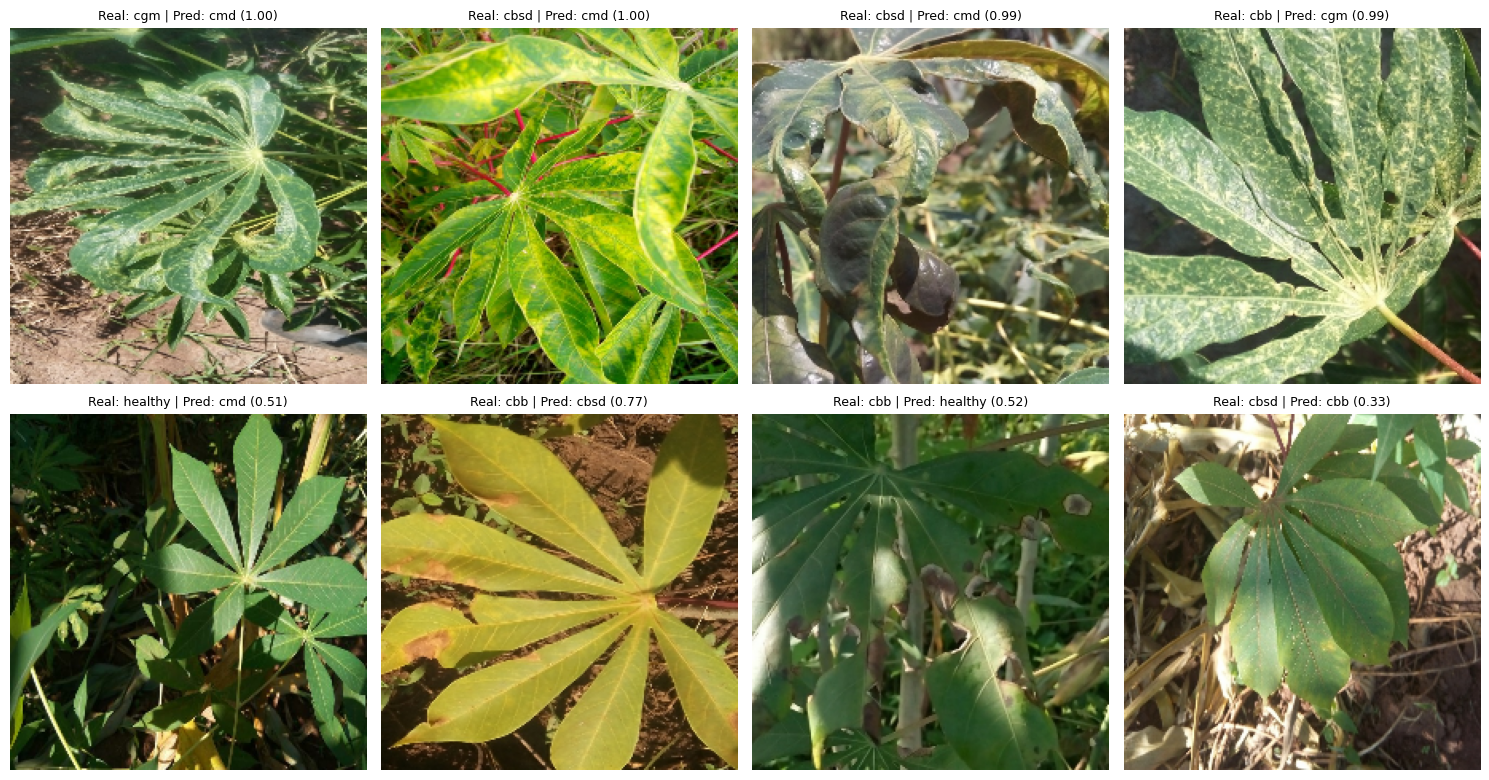

11

In [12]:
indices_error = np.flatnonzero(y_pred != y_true)
confianza = probabilidades.max(axis=1)
assert len(indices_error) >= 8, "Se necesitan al menos ocho errores para esta inspección"

rng = np.random.default_rng(SEED)
altos = indices_error[np.argsort(-confianza[indices_error])[:4]]
restantes = np.setdiff1d(indices_error, altos)
aleatorios = rng.choice(restantes, size=4, replace=False)
seleccion = np.concatenate([altos, aleatorios])

# Solo se guardan ocho imágenes uint8, no las 1.877 de validación.
objetivos = set(int(i) for i in seleccion)
imagenes = {}
posicion = 0
for lote_x, _ in val_ds:
    for img in lote_x:
        if posicion in objetivos:
            imagenes[posicion] = np.clip(img.numpy(), 0, 255).astype(np.uint8)
        posicion += 1
    if len(imagenes) == len(objetivos):
        break
assert len(imagenes) == 8

fig, ejes = plt.subplots(2, 4, figsize=(15, 8))
for ax, indice in zip(ejes.flat, seleccion):
    indice = int(indice)
    ax.imshow(imagenes[indice])
    ax.set_title(f"Real: {CLASS_NAMES[y_true[indice]]} | "
                 f"Pred: {CLASS_NAMES[y_pred[indice]]} ({confianza[indice]:.2f})", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "errores_inspeccionados.png"), dpi=180)
plt.show()
plt.close(fig)

pd.DataFrame({
    "indice_validacion": seleccion,
    "clase_real": [CLASS_NAMES[y_true[i]] for i in seleccion],
    "clase_predicha": [CLASS_NAMES[y_pred[i]] for i in seleccion],
    "confianza": confianza[seleccion],
}).to_csv(os.path.join(OUTPUT_DIR, "errores_inspeccionados.csv"), index=False)
del imagenes
gc.collect()

## 11. Descargar resultados

Ejecuta esta celda antes de cerrar Colab: los archivos de `/content` se borran al terminar la sesión.

In [13]:
!zip -r e2_resultados.zip results/e2
from google.colab import files
files.download("e2_resultados.zip")

  adding: results/e2/ (stored 0%)
  adding: results/e2/matriz_confusion.csv (deflated 25%)
  adding: results/e2/comparacion_e1_e2.csv (deflated 35%)
  adding: results/e2/resumen_metricas.csv (deflated 33%)
  adding: results/e2/errores_inspeccionados.csv (deflated 37%)
  adding: results/e2/curvas_entrenamiento.png (deflated 12%)
  adding: results/e2/errores_inspeccionados.png (deflated 0%)
  adding: results/e2/historial_entrenamiento.csv (deflated 45%)
  adding: results/e2/reporte_clasificacion.csv (deflated 51%)
  adding: results/e2/matriz_confusion.png (deflated 19%)
  adding: results/e2/mejor_modelo_e2.keras (deflated 11%)
  adding: results/e2/comparacion_f1_por_clase_e1_e2.csv (deflated 42%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>